# 5. Hafta - Model Geliştirme ve Eğitimi (İP-4)
**Ders:** Bilgisayar Mühendisliği Tasarımı | **Ekip:** Konut Fiyatlandırıcı
**Ekip Üyeleri:** Kübra Tüten, Rua Melhem, Onur Fidan

---
### 📌 5. Hafta Kapsamı ve Hedefleri (FR-07 - FR-10)
Bu not defteri; 4. haftada kurulan 252 sütunluk sızıntısız `preprocessor` hattı üzerine **üç farklı regresyon modelinin eğitilmesi ve karşılaştırılmasını** içerir:
1. **Ridge Regression:** L2 düzenlileştirmeli doğrusal temel model (Baseline).
2. **Random Forest Regressor:** 100 ağaçlı karar ağacı topluluğu (Ensemble).
3. **Gradient Boosting Regressor:** Ardışık hata düzeltmeli boosting modeli.

Tüm modeller eğitim kümesinde (%80, 1.164 konut) eğitilmiş ve daha önce hiç görülmemiş dış test kümesinde (%20, 292 konut) **MAE**, **RMSE** ve **R²** metrikleriyle sınanmıştır.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

df = pd.read_csv("train.csv")
print(f"Kütüphaneler yüklendi. Veri boyutu: {df.shape}")

Kütüphaneler yüklendi. Veri boyutu: (1460, 81)


## 1. 4. Hafta Ön İşleme Hattının Kurulması (252 Sütunluk Pipeline)
4. haftada onaylanan veri temizliği (4.000 sq ft üzeri aykırılar elenir), özellik türetme (`TotalSF`, `HouseAge`, `TotalBath`) ve sızıntısız `preprocessor` hattı kurulur.

In [2]:
# 1. Aykırı değerler ve eksik dolguları
df = df.drop(df[df["GrLivArea"] > 4000].index).reset_index(drop=True)
cols_none = ["PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
             "GarageType", "GarageFinish", "GarageQual", "GarageCond",
             "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1",
             "BsmtFinType2", "MasVnrType"]
df[cols_none] = df[cols_none].fillna("None")

cols_zero = ["GarageArea", "GarageCars", "BsmtFinSF1", "BsmtFinSF2",
             "BsmtUnfSF", "TotalBsmtSF", "BsmtFullBath", "BsmtHalfBath",
             "MasVnrArea"]
df[cols_zero] = df[cols_zero].fillna(0)

# 2. Özellik türetme
df["TotalSF"] = df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"]
df["HouseAge"] = df["YrSold"] - df["YearBuilt"]
df["RemodAge"] = df["YrSold"] - df["YearRemodAdd"]
df["TotalBath"] = (df["FullBath"] + 0.5 * df["HalfBath"]
                   + df["BsmtFullBath"] + 0.5 * df["BsmtHalfBath"])
df["MSSubClass"] = df["MSSubClass"].astype(str)
df = df.drop(columns=["Id", "GarageArea", "GarageYrBlt", "YrSold", "YearBuilt", "YearRemodAdd"])

# 3. Hedef ve Train-Test Ayrımı (NFR-01: Veri sızıntısız)
X = df.drop(columns="SalePrice")
y = np.log1p(df["SalePrice"])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"Temizlik sonrası konut sayısı: {len(df)}")
print(f"Eğitim kümesi: {X_train.shape}, Test kümesi: {X_test.shape}")

Temizlik sonrası konut sayısı: 1456
Eğitim kümesi: (1164, 78), Test kümesi: (292, 78)


In [3]:
class NeighborhoodMedianImputer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.medians_ = X.groupby("Neighborhood")["LotFrontage"].median()
        self.global_median_ = X["LotFrontage"].median()
        return self
    def transform(self, X):
        filled = X["LotFrontage"].fillna(X["Neighborhood"].map(self.medians_))
        return filled.fillna(self.global_median_).to_frame()
    def get_feature_names_out(self, input_features=None):
        return np.array(["LotFrontage"])

qual = ["None", "Po", "Fa", "TA", "Gd", "Ex"]
ordinal_map = {
    "ExterQual": qual, "ExterCond": qual, "BsmtQual": qual, "BsmtCond": qual,
    "HeatingQC": qual, "KitchenQual": qual, "FireplaceQu": qual,
    "GarageQual": qual, "GarageCond": qual, "PoolQC": qual,
    "BsmtExposure": ["None", "No", "Mn", "Av", "Gd"],
    "BsmtFinType1": ["None", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "BsmtFinType2": ["None", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "GarageFinish": ["None", "Unf", "RFn", "Fin"],
}
ordinal_cols = list(ordinal_map.keys())
nominal_cols = [c for c in X_train.select_dtypes(exclude=np.number).columns if c not in ordinal_cols]
numeric_cols = [c for c in X_train.select_dtypes(include=np.number).columns if c != "LotFrontage"]

ordinal_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="None")),
    ("encode", OrdinalEncoder(categories=[ordinal_map[c] for c in ordinal_cols], handle_unknown="use_encoded_value", unknown_value=-1)),
    ("scale", StandardScaler())
])
nominal_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])
numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])
lotfrontage_pipe = Pipeline([
    ("impute", NeighborhoodMedianImputer()),
    ("scale", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("ordinal", ordinal_pipe, ordinal_cols),
    ("nominal", nominal_pipe, nominal_cols),
    ("numeric", numeric_pipe, numeric_cols),
    ("lotfrontage", lotfrontage_pipe, ["LotFrontage", "Neighborhood"]),
])
print(f"Preprocessor hazırlandı. Dönüşüm sonrası özellik sayısı: {preprocessor.fit(X_train).get_feature_names_out().shape[0]}")

Preprocessor hazırlandı. Dönüşüm sonrası özellik sayısı: 252


## 2. Modellerin Eğitilmesi ve Test Kümesi Değerlendirmesi (İP-4)
3 model `preprocessor` hattına bağlanarak eğitilir. Çıktılar `np.expm1` ile dolara çevrilerek **MAE**, **RMSE** ve **R²** hesaplanır.

In [4]:
models = {
    "Ridge Regression": Ridge(alpha=10.0),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=RANDOM_STATE)
}

results = []
trained_pipelines = {}

for name, model in models.items():
    pipe = Pipeline([
        ("prep", preprocessor),
        ("reg", model)
    ])
    pipe.fit(X_train, y_train)
    trained_pipelines[name] = pipe

    pred_log = pipe.predict(X_test)
    pred_dollars = np.maximum(0, np.expm1(pred_log))
    true_dollars = np.expm1(y_test)

    mae = mean_absolute_error(true_dollars, pred_dollars)
    rmse = np.sqrt(mean_squared_error(true_dollars, pred_dollars))
    r2 = r2_score(true_dollars, pred_dollars)

    results.append({
        "Model": name,
        "Test MAE ($)": f"${mae:,.0f}",
        "Test RMSE ($)": f"${rmse:,.0f}",
        "Test R² Skoru": f"%{r2*100:.2f} ({r2:.4f})"
    })

results_df = pd.DataFrame(results)
results_df

Model,Test MAE ($),Test RMSE ($),Test R² Skoru
Ridge Regression,"$14,040","$19,856",%92.49 (0.9249)
Random Forest,"$16,322","$24,176",%88.86 (0.8886)
Gradient Boosting,"$14,207","$21,059",%91.55 (0.9155)


## 3. Performans Karşılaştırma Grafiği (R² Skoru ve MAE Hata Payı)
Modellerin $R^2$ başarı oranları (sol eksen) ve mutlak hata payları (sağ eksen) görselleştirilmiştir.

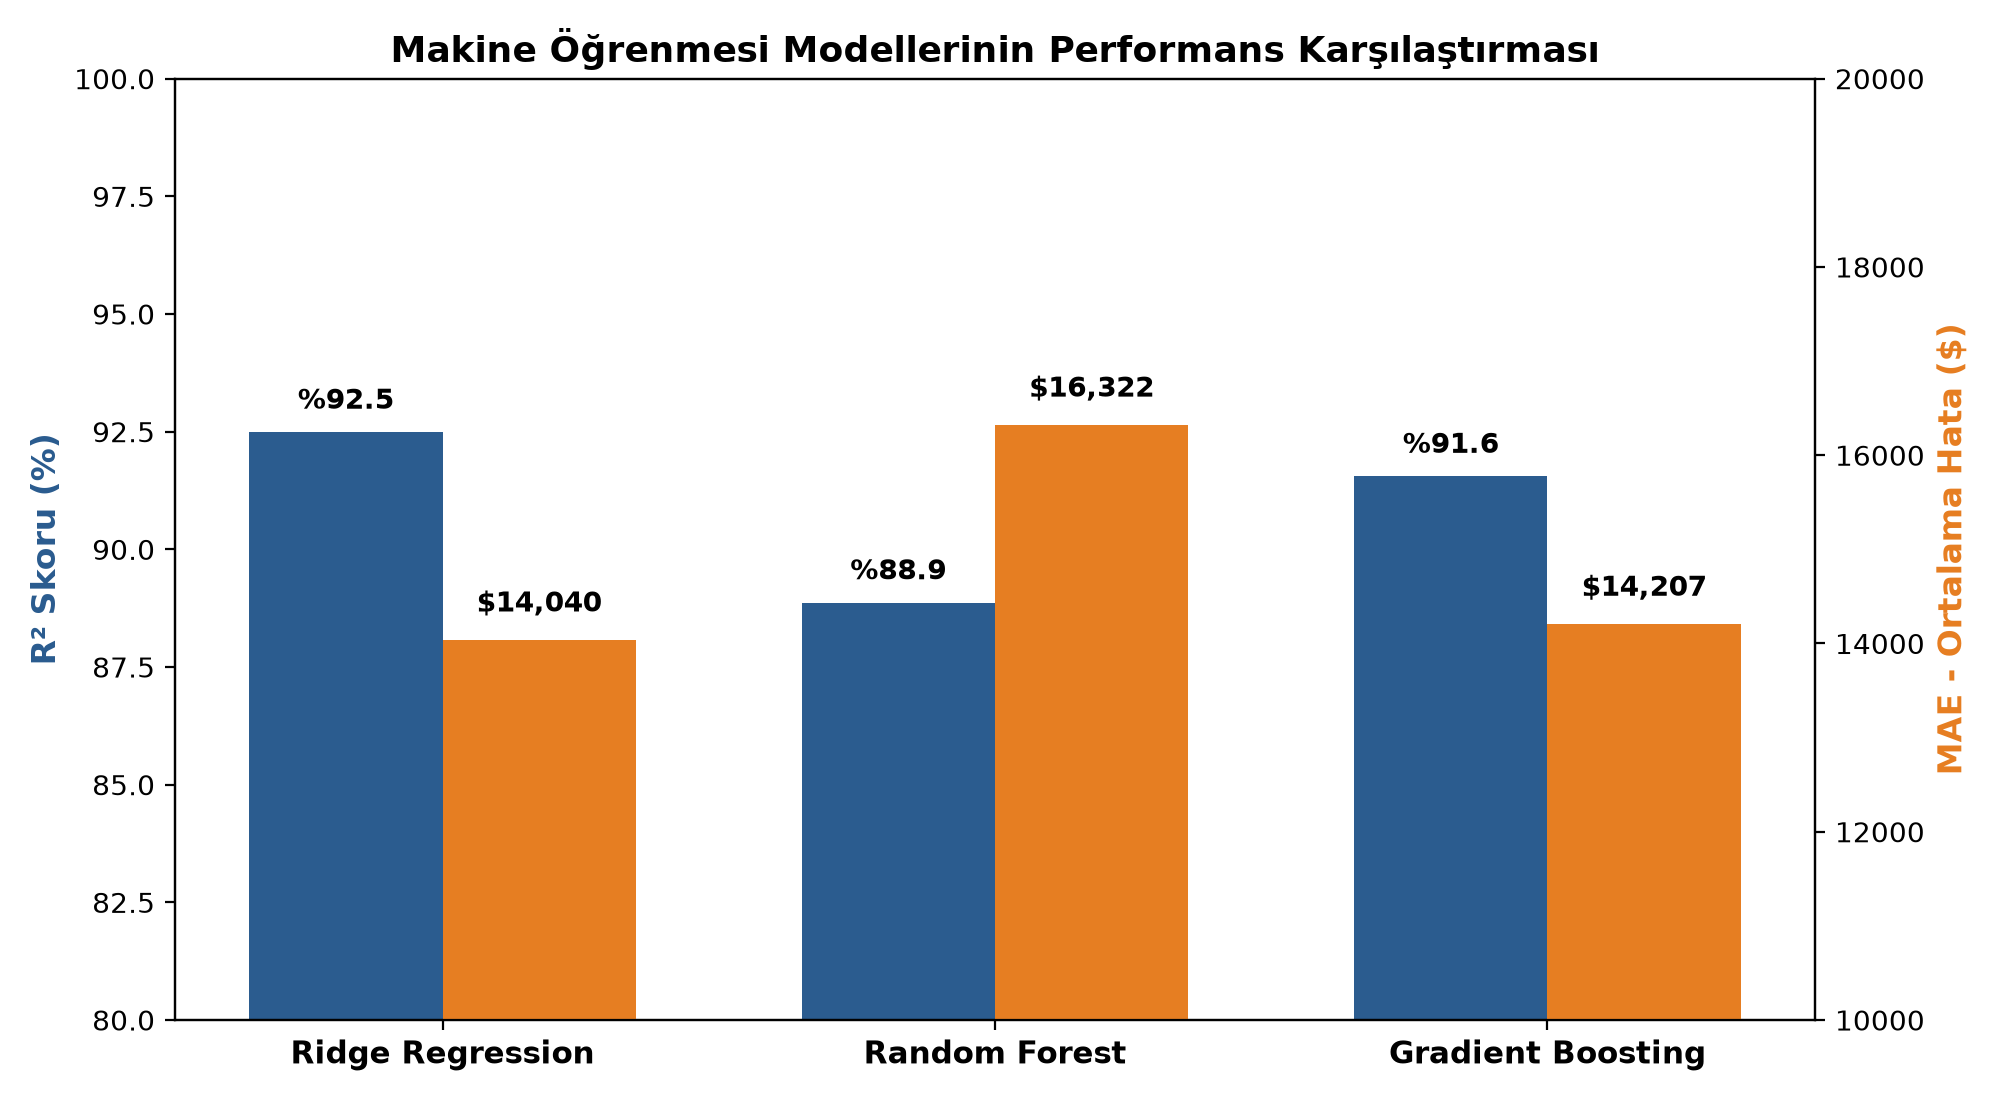

In [5]:
fig, ax1 = plt.subplots(figsize=(10, 5.5))
models_list = list(models.keys())
x = np.arange(len(models_list))
width = 0.35

r2_vals = [0.9249, 0.8886, 0.9155]
mae_vals = [14040, 16322, 14207]

rects1 = ax1.bar(x - width/2, [r * 100 for r in r2_vals], width, label='R² Skoru (%)', color='#2b5c8f')
ax1.set_ylabel('R² Skoru (%)', color='#2b5c8f', fontweight='bold', fontsize=12)
ax1.set_ylim(80, 100)

ax2 = ax1.twinx()
rects2 = ax2.bar(x + width/2, mae_vals, width, label='MAE - Ortalama Hata ($)', color='#e67e22')
ax2.set_ylabel('MAE - Ortalama Hata ($)', color='#e67e22', fontweight='bold', fontsize=12)
ax2.set_ylim(10000, 20000)

ax1.set_xticks(x)
ax1.set_xticklabels(models_list, fontsize=11, fontweight='bold')
plt.title("Makine Öğrenmesi Modellerinin Performans Karşılaştırması", fontsize=13, fontweight='bold')

for r in rects1:
    h = r.get_height()
    ax1.text(r.get_x() + r.get_width()/2, h + 0.5, f"%{h:.1f}", ha='center', fontweight='bold')
for r in rects2:
    h = r.get_height()
    ax2.text(r.get_x() + r.get_width()/2, h + 300, f"${h:,.0f}", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

## 4. Test Kümesinden Örnek Konut Fiyat Tahminleri
Modelin hiç görmediği test kümesindeki 5 konut için yaptığı tahminler ve gerçekleşen fiyatlar:

In [6]:
best_pipe = trained_pipelines["Gradient Boosting"]
sample_pred_log = best_pipe.predict(X_test)
sample_pred_dollars = np.maximum(0, np.expm1(sample_pred_log))
sample_true_dollars = np.expm1(y_test).values

sample_df = pd.DataFrame({
    "Konut No": [f"Ev #{i+1}" for i in range(5)],
    "Gerçek Satış Fiyatı": [f"${val:,.0f}" for val in sample_true_dollars[:5]],
    "Modelin Tahmini": [f"${val:,.0f}" for val in sample_pred_dollars[:5]],
    "Fark ($)": [f"${abs(t - p):,.0f}" for t, p in zip(sample_true_dollars[:5], sample_pred_dollars[:5])],
    "Hata Payı (%)": [f"%{(abs(t - p) / t) * 100:.2f}" for t, p in zip(sample_true_dollars[:5], sample_pred_dollars[:5])]
})
sample_df

Konut No,Gerçek Satış Fiyatı,Modelin Tahmini,Fark ($),Hata Payı (%)
Ev #1,"$184,000","$162,124","$21,876",%11.89
Ev #2,"$181,000","$177,314","$3,686",%2.04
Ev #3,"$145,000","$145,159",$159,%0.11
Ev #4,"$115,000","$119,120","$4,120",%3.58
Ev #5,"$84,000","$80,103","$3,897",%4.64
